# 2 · Volatility dynamics: GJR-GARCH(1,1) with Student-t errors
GJR-GARCH captures **volatility clustering** (high persistence β), **asymmetry** (γ > 0: bad news raises volatility more than good news) and **fat tails** (low t degrees of freedom).
Each asset is fitted on the full 2018-2024 sample, and the pre-COVID and post-COVID regimes are then fitted separately to see whether the volatility process changed.

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("../images"); IMG.mkdir(exist_ok=True)
from covidmkt import data as D
px = D.load_prices("../data/prices.csv")          # refresh: python scripts/fetch_data.py
rets = D.log_returns(px)
def shade(ax):
    for p, (s, e) in D.PERIODS.items():
        ax.axvspan(pd.Timestamp(s), pd.Timestamp(e), color=D.PERIOD_COLORS[p], alpha=0.07)
print(f"{len(px):,} trading days, {px.shape[1]} series, {px.index[0]:%Y-%m-%d} -> {px.index[-1]:%Y-%m-%d}")
from covidmkt import volatility as V

1,761 trading days, 15 series, 2018-01-02 -> 2024-12-31


In [2]:
sel = ["SPY", "EEM", "HYG", "TLT", "GC=F", "USO", "EURUSD=X", "BTC-USD"]
fits = {t: V.fit_gjr(rets[t]) for t in sel}
tbl = pd.DataFrame({D.ASSETS.loc[t, "name"]: V.summarize(r) for t, r in fits.items()}).T
tbl.style.format("{:.3f}").format({"half-life (days)": "{:.0f}", "log-lik": "{:.0f}"})

,omega,alpha,gamma (leverage),beta,persistence,half-life (days),nu (t dof),log-lik
US large caps,0.033166,0.003307,0.261493,0.838804,0.972857,25,6.336676,-2367
EM equities,0.077126,0.037459,0.112941,0.854065,0.947995,13,10.672357,-2769
High yield,0.001366,0.019370,0.174497,0.893002,0.999620,1825,7.991753,-739
Long Treasuries,0.017280,0.087721,-0.002044,0.897132,0.983831,43,18.892470,-2339
Gold,0.013638,0.060632,-0.035338,0.947903,0.990866,76,4.072897,-2245
Crude oil,0.196503,0.037093,0.097638,0.868130,0.954042,15,6.477116,-3750
EUR/USD,0.001331,0.031489,0.000414,0.961629,0.993324,103,8.564534,-1001
Bitcoin,0.370505,0.093582,-0.014916,0.913876,1.000000,inf,2.988710,-4775


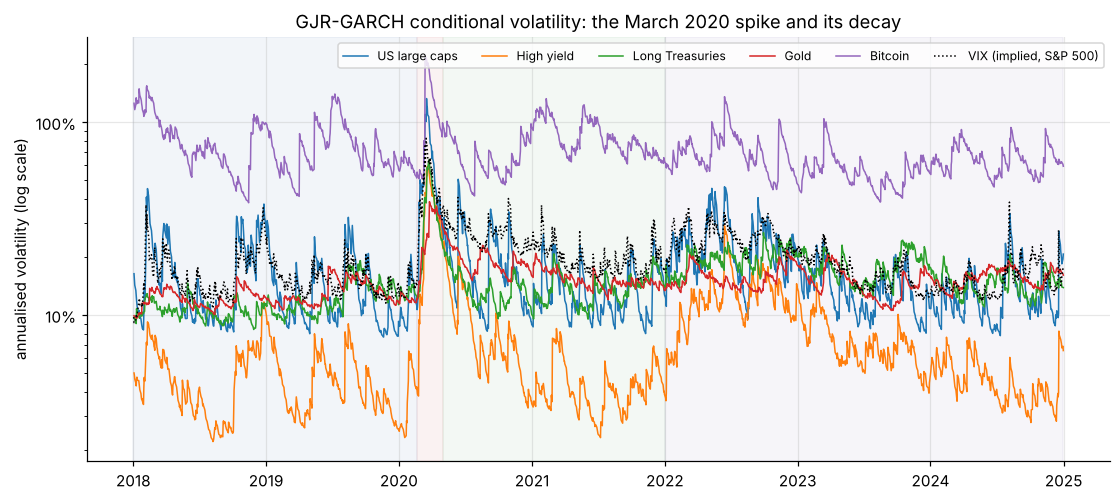

In [3]:
fig, ax = plt.subplots(figsize=(12, 5))
for t in ["SPY", "HYG", "TLT", "GC=F", "BTC-USD"]:
    ax.plot(V.conditional_vol(fits[t]), label=D.ASSETS.loc[t, "name"], lw=1)
ax.plot(px["^VIX"] / 100, color="k", ls=":", lw=1, label="VIX (implied, S&P 500)")
shade(ax); ax.set_yscale("log"); ax.set_ylabel("annualised volatility (log scale)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}")); ax.legend(ncol=6, fontsize=8)
ax.set_title("GJR-GARCH conditional volatility: the March 2020 spike and its decay")
plt.savefig(IMG / "garch_conditional_vol.png", bbox_inches="tight"); plt.show()

In [4]:
spy_vol = V.conditional_vol(fits["SPY"])
print(f"Correlation of GARCH SPY volatility with VIX: {spy_vol.corr(px['^VIX'].reindex(spy_vol.index)):.3f}")
print(f"Peak GARCH SPY vol: {spy_vol.max():.0%} on {spy_vol.idxmax():%d %b %Y}; peak VIX: {px['^VIX'].max():.1f} on {px['^VIX'].idxmax():%d %b %Y}")
vix = px["^VIX"].reindex(spy_vol.index) / 100
print(f"VIX above GARCH vol on {(vix > spy_vol).mean():.0%} of days; average gap {(vix - spy_vol).mean():+.1%} (variance risk premium)")

Correlation of GARCH SPY volatility with VIX: 0.848
Peak GARCH SPY vol: 133% on 17 Mar 2020; peak VIX: 82.7 on 16 Mar 2020
VIX above GARCH vol on 79% of days; average gap +2.7% (variance risk premium)


## Did the volatility process change? Pre- vs post-COVID fits

In [5]:
rows = []
for t in sel:
    for p in ("Pre-COVID", "Post-COVID"):
        s = V.summarize(V.fit_gjr(D.period_slice(rets[t], p)))
        rows.append({"asset": D.ASSETS.loc[t, "name"], "period": p, **{k: s[k] for k in ("alpha", "gamma (leverage)", "beta", "persistence")},
                     # unconditional variance only exists when persistence < 1
                     "uncond. vol": np.sqrt(252 * s["omega"] / (1 - s["persistence"])) / 100 if s["persistence"] < 0.999 else np.nan})
cmp_ = pd.DataFrame(rows).pivot(index="asset", columns="period")
cmp_.round(3)

alpha           gamma (leverage)                 beta  \
period          Post-COVID Pre-COVID       Post-COVID Pre-COVID Post-COVID   
asset                                                                        
Bitcoin              0.051     0.089           -0.024     0.033      0.952   
Crude oil            0.087     0.000           -0.001     0.069      0.895   
EM equities          0.004     0.023            0.064     0.164      0.950   
EUR/USD              0.000     0.000            0.031    -0.000      0.983   
Gold                 0.104     0.030           -0.104    -0.030      0.848   
High yield           0.000     0.011            0.066     0.253      0.965   
Long Treasuries      0.000     0.030            0.029    -0.030      0.985   
US large caps        0.000     0.000            0.109     0.328      0.932   

                          persistence           uncond. vol            
period          Pre-COVID  Post-COVID Pre-COVID  Post-COVID Pre-COVID  
asset                                                                  
Bitcoin             0.895       0.991     1.000       0.845       NaN  
Crude oil           0.931       0.982     0.965       0.357     0.287  
EM equities         0.815       0.986     0.920       0.184     0.180  
EUR/USD             0.996       0.998     0.996       0.083     0.029  
Gold                0.960       0.900     0.974       0.153     0.117  
High yield          0.843       0.998     0.980       0.076     0.054  
Long Treasuries     0.983       0.999     0.998         NaN     0.133  
US large caps       0.786       0.986     0.950       0.150     0.137

**Reading the results**
* Persistence (α + β + γ/2) is close to 1 for most assets, so volatility shocks decay slowly. Half-lives run from weeks to months.
* Equities and high yield show a large leverage term γ: falling prices raise volatility more than rising prices.
* Bitcoin has the fattest tails (lowest ν) and the highest volatility level, but almost no leverage effect.
* GARCH volatility for SPY tracks the VIX closely (correlation about 0.85), and the VIX usually sits above it. That gap is the variance risk premium investors pay for crash protection.
* **Regime change:** fitted separately, post-COVID volatility is *more persistent* for most assets, and the equity leverage effect is much weaker than before 2020 (US large caps γ ≈ 0.33 → 0.11). The 2022 sell-off came through rates and inflation rather than panic. A blank unconditional volatility means persistence ≈ 1 (an integrated, IGARCH-like process).